# Figure S16: Ancestry enrichment across allele frequencies

Ancestry enrichment and cross-population allele sharing across allele-frequency bins.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_INPUT_ROOT` to the
source result tables and `QTL_SUSIE_ROOT` to the separate fine-mapping tables.
Set `QTL_PAPER_ROOT` to the local reference directory and `QTL_SOURCE_ROOT`
to the figure checkout. Set these variables in R before running the cells.
Paths can contain spaces.

Run the cells from top to bottom. The cells show input reads, filters, joins,
counts, models, and plot construction. Intermediate objects stay in this R
session. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Source scripts

The processing steps below follow these preparation scripts. The source data are not included in Git.

- [fig2_data](../../preparation/Fig2/build.R): Prepare current frequency bins, unique-variant ancestry tests, consequence-priority aFC data and regressions, cumulative aFC summaries, outlier statistics from contingency counts, protein-coding medians, and S16 ancestry bins.

The notebook runs the processing in its own cells. The preparation guide lists the original input requirements and missing inputs.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
input_root <- Sys.getenv("QTL_INPUT_ROOT", source_root)
susie_root <- Sys.getenv("QTL_SUSIE_ROOT", input_root)
repo_root <- getwd()
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  if (grepl("[.]rds([.]gz)?$", relative, ignore.case = TRUE)) {
    stop("Saved RDS inputs are not used by these notebooks: ", relative, call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || dir.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  key <- paste(variable, relative, sep = ":")
  hash <- unname(tools::md5sum(path))
  previous <- input_records[[key]]
  if (!is.null(previous) && !identical(previous$md5, hash)) {
    stop("Input changed during notebook execution: ", relative, call. = FALSE)
  }
  if (is.null(previous)) input_records[[key]] <- list(root = variable, path = relative, md5 = hash)
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
input_file <- function(relative) checked_input(input_root, relative, "QTL_INPUT_ROOT")
susie_file <- function(relative) checked_input(susie_root, relative, "QTL_SUSIE_ROOT")
repo_file <- function(relative) checked_input(repo_root, relative, "QTL_REPO_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")
# Local source-result inputs and memory-only intermediate objects.
prep_root <- function(name) {
  value <- switch(name, paper = paper_root, source = source_root,
                  input = input_root, susie = susie_root,
                  stop("Unknown source root: ", name, call. = FALSE))
  if (!nzchar(value)) stop("Set the local ", name, " root before running the notebook.", call. = FALSE)
  value
}
.prep_root <- prep_root
prep_input <- function(root_name, relative) {
  variable <- c(paper = "QTL_PAPER_ROOT", source = "QTL_SOURCE_ROOT",
                input = "QTL_INPUT_ROOT", susie = "QTL_SUSIE_ROOT")[[root_name]]
  checked_input(prep_root(root_name), relative, variable)
}
prep_input_any <- function(root_name, candidates) {
  for (relative in candidates) {
    if (file.exists(file.path(prep_root(root_name), relative))) return(prep_input(root_name, relative))
  }
  stop("Missing source input under ", root_name, ": ", paste(candidates, collapse = ", "), call. = FALSE)
}
prep_input_file <- function(variable, fallback_root = "input", relative) {
  path <- Sys.getenv(variable)
  if (!nzchar(path)) return(prep_input_any(fallback_root, relative))
  checked_input(dirname(path), basename(path), paste0("env:", variable))
}
# Resolve recorded paths for the input-unchanged check. Records contain no
# machine-specific directory names; explicit file overrides retain their key.
recorded_input_path <- function(record) {
  if (startsWith(record$root, "env:")) return(Sys.getenv(sub("^env:", "", record$root)))
  root <- switch(record$root, QTL_PAPER_ROOT = paper_root,
                 QTL_SOURCE_ROOT = source_root, QTL_INPUT_ROOT = input_root,
                 QTL_SUSIE_ROOT = susie_root, QTL_REPO_ROOT = repo_root,
                 stop("Unknown recorded input root: ", record$root, call. = FALSE))
  file.path(root, record$path)
}

# These functions read the tracked result-table manifest. Each notebook starts
# with an empty memory store. An existing file cannot skip a calculation.
prep_result_runtime <- function(figure, envir = parent.frame()) {
  manifest <- readr::read_tsv(repo_file(file.path(figure, "inputs.tsv")),
    col_types = cols(.default = col_character()), na = c("", "-"), show_col_types = FALSE)
  computed <- new.env(parent = emptyenv())
  input_files <- function(key) {
    rows <- manifest[manifest$key == key, , drop = FALSE]
    if (!nrow(rows)) stop("Unknown result-table key: ", key, call. = FALSE)
    rows$path <- map_chr(rows$local_subpath, function(relative) {
      if (key == "clingen") {
        files <- list.files(file.path(prep_root("input"), relative), pattern = "[.]parquet$", full.names = FALSE)
        if (!length(files)) stop("No ClinGen parquet input under ", relative, call. = FALSE)
        return(prep_input("input", file.path(relative, sort(files)[1])))
      }
      candidates <- unique(c(relative, sub("splicing_SusieMerged[.]annotated", "splicing_SusieMerged..annotated", relative)))
      prep_input_any("input", candidates)
    })
    rows
  }
  input_path <- function(key) {
    rows <- input_files(key)
    if (nrow(rows) != 1L) stop("Expected one input for ", key, call. = FALSE)
    rows$path
  }
  load_input <- function(key, reader = data.table::fread, ..., attach_meta = TRUE) {
    rows <- input_files(key)
    metadata <- setdiff(names(rows), c("key", "local_subpath", "gs_uri", "source_repo", "source_workflow", "path"))
    map_dfr(seq_len(nrow(rows)), function(i) {
      data <- as_tibble(reader(rows$path[i], ...))
      if (attach_meta) for (column in metadata) if (!is.na(rows[[column]][i])) data[[column]] <- rows[[column]][i]
      data
    })
  }
  build_or_cache <- function(name, expr, refresh = FALSE) {
    if (!refresh && exists(name, envir = computed, inherits = FALSE)) return(computed[[name]])
    message("Calculate ", figure, "/", name, " from source result tables")
    value <- force(expr)
    computed[[name]] <- value
    value
  }
  for (name in c("input_files", "input_path", "load_input", "build_or_cache")) assign(name, get(name), envir = envir)
  invisible(computed)
}


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Source ancestry methods

Recalculate the ancestry-frequency summaries from the combined expression
SuSiE result table. The source result rows contain the ancestry OR and P value.


In [2]:
# Data methods retained from the current local Fig2/00_setup.R.
# The source SHA-256 is recorded in the preparation manifest.
# Source result tables are the boundary; no association mapping is run.
suppressPackageStartupMessages(library(tidyverse))

add_derived <- function(df) {
  df %>% mutate(
    rare       = gvs_max_af < 0.01,
    odds_ratio = as.numeric(gvs_odds_ratio),
    p_value    = as.numeric(gvs_p_value)
  )
}

make_cumulative_afc_curve_both <- function(df,
                                           gene_col = "gene",
                                           afc_col  = "log2_aFC",
                                           down_thresholds = c(0.75, 0.65, 0.60, 0.55),
                                           up_thresholds   = c(1.10, 1.25, 1.40, 1.50, 2.00, 2.50, 3.00),
                                           max_k = NULL) {
  gene_sym <- rlang::sym(gene_col)
  afc_sym  <- rlang::sym(afc_col)

  df_clean  <- df %>% dplyr::filter(!is.na(!!gene_sym), !is.na(!!afc_sym))
  all_genes <- df_clean %>% dplyr::distinct(!!gene_sym) %>% dplyr::transmute(gene = !!gene_sym)

  build_direction <- function(data, direction, thresholds) {
    df_use <- if (direction == "down") {
      data %>% dplyr::filter(!!afc_sym < 0) %>% dplyr::arrange(!!gene_sym, !!afc_sym)
    } else {
      data %>% dplyr::filter(!!afc_sym > 0) %>% dplyr::arrange(!!gene_sym, dplyr::desc(!!afc_sym))
    }

    if (nrow(df_use) == 0) {
      cumulative_df <- tibble::tibble(gene = character(), n_variants = integer(),
        cumulative_log2_aFC = numeric(), cumulative_aFC = numeric(),
        expected_het_expr = numeric(), direction = character())
      min_n_by_thresh <- tidyr::expand_grid(gene = all_genes$gene, threshold = thresholds) %>%
        dplyr::mutate(min_n = Inf, direction = direction)
      return(list(cumulative_df = cumulative_df, min_n_by_thresh = min_n_by_thresh))
    }

    cumulative_df <- df_use %>%
      dplyr::group_by(!!gene_sym) %>%
      dplyr::mutate(
        n_variants          = dplyr::row_number(),
        cumulative_log2_aFC = cumsum(!!afc_sym),
        cumulative_aFC      = 2^cumulative_log2_aFC,
        expected_het_expr   = (1 + cumulative_aFC) / 2
      ) %>%
      dplyr::ungroup() %>%
      dplyr::transmute(gene = !!gene_sym, n_variants, cumulative_log2_aFC,
                       cumulative_aFC, expected_het_expr, direction = direction)

    min_n_by_thresh <- purrr::map_dfr(thresholds, function(thresh) {
      hits <- if (direction == "down") {
        cumulative_df %>% dplyr::filter(expected_het_expr <= thresh)
      } else {
        cumulative_df %>% dplyr::filter(expected_het_expr >= thresh)
      }
      min_n <- hits %>% dplyr::group_by(gene) %>%
        dplyr::summarise(min_n = min(n_variants), .groups = "drop")
      all_genes %>%
        dplyr::left_join(min_n, by = "gene") %>%
        dplyr::mutate(threshold = thresh,
                      min_n = dplyr::if_else(is.na(min_n), Inf, as.numeric(min_n)),
                      direction = direction)
    })

    list(cumulative_df = cumulative_df, min_n_by_thresh = min_n_by_thresh)
  }

  down_res <- build_direction(df_clean, "down", down_thresholds)
  up_res   <- build_direction(df_clean, "up",   up_thresholds)

  cumulative_df   <- dplyr::bind_rows(down_res$cumulative_df, up_res$cumulative_df)
  min_n_by_thresh <- dplyr::bind_rows(down_res$min_n_by_thresh, up_res$min_n_by_thresh)

  if (is.null(max_k)) {
    finite_vals <- min_n_by_thresh$min_n[is.finite(min_n_by_thresh$min_n)]
    max_k <- if (length(finite_vals) == 0) 1 else max(finite_vals)
  }

  curve_df <- tidyr::expand_grid(direction = c("down", "up"),
                                 threshold = c(down_thresholds, up_thresholds),
                                 k = seq_len(max_k)) %>%
    dplyr::filter((direction == "down" & threshold %in% down_thresholds) |
                    (direction == "up" & threshold %in% up_thresholds)) %>%
    dplyr::rowwise() %>%
    dplyr::mutate(prop_genes = mean(
      min_n_by_thresh$min_n[min_n_by_thresh$direction == direction &
                              min_n_by_thresh$threshold == threshold] <= k)) %>%
    dplyr::ungroup()

  list(cumulative_df = cumulative_df, min_n_by_thresh = min_n_by_thresh, curve_df = curve_df)
}

# Current display-data methods from the November 2 figure sources.
# The input unit is a saved QTL result row. No participant-level input is used.

fig2_frequency_counts <- function(assay_tables) {
  dat <- purrr::imap_dfr(assay_tables, ~mutate(.x, Assay = .y))
  stopifnot(all(is.na(dat$pip) | between(dat$pip, 0, 1)))
  kept <- dat %>% filter(pip > 0.9, !is.na(gvs_max_af), gvs_max_af > 0)
  stopifnot(all(is.finite(kept$gvs_max_af)), all(kept$gvs_max_af <= 0.5))
  bins <- c("<1%", "1–<5%", "5–<10%", "10–50%")
  kept <- kept %>% mutate(Assay = factor(Assay, names(assay_tables)),
                         frequency_bin = factor(case_when(gvs_max_af < 0.01 ~ bins[1],
                                                          gvs_max_af < 0.05 ~ bins[2],
                                                          gvs_max_af < 0.10 ~ bins[3], TRUE ~ bins[4]), bins))
  counts <- kept %>% count(Assay, frequency_bin, .drop = FALSE) %>%
    group_by(Assay) %>% mutate(total = sum(n), percent = 100 * n / total) %>% ungroup()
  qc <- dat %>% group_by(Assay) %>%
    summarise(input_rows = n(), pip_above_09 = sum(pip > 0.9, na.rm = TRUE),
              missing_af = sum(pip > 0.9 & is.na(gvs_max_af), na.rm = TRUE),
              nonpositive_af = sum(pip > 0.9 & gvs_max_af <= 0, na.rm = TRUE), .groups = "drop")
  list(counts = counts, qc = qc)
}

fig2_ancestry_data <- function(assay_tables) {
  columns <- c("variant", "pip", "gvs_max_subpop", "gvs_max_af", "odds_ratio", "p_value", "rare")
  skew_df <- map_dfr(assay_tables, ~select(add_derived(.x), all_of(columns))) %>%
    filter(pip > 0.9, !is.na(gvs_max_subpop)) %>% distinct(variant, .keep_all = TRUE) %>%
    mutate(padj = p.adjust(p_value, method = "fdr"), enriched = odds_ratio > 5 & padj < 0.05,
           pop = toupper(gvs_max_subpop), rare_lab = if_else(rare, "Rare", "Common"))
  skew_counts <- skew_df %>% filter(enriched) %>% distinct(variant, pop) %>% count(pop)
  or_min <- min(skew_df$odds_ratio[skew_df$odds_ratio > 0], na.rm = TRUE)
  pair_line_df <- skew_df %>% distinct(pop) %>%
    mutate(x = as.numeric(factor(pop)) - 0.32, xend = as.numeric(factor(pop)) + 0.32,
           y = or_min * 0.55, yend = or_min * 0.55)
  label_df <- tibble(rare_lab = c("Common", "Rare"), x = 1 + c(-0.2, 0.2), y = or_min * 0.32)
  list(skew_df = skew_df, skew_counts = skew_counts, or_min = or_min,
       pair_line_df = pair_line_df, label_df = label_df)
}

# The saved enrichment result carries the four contingency counts. Its OR and
# Wald interval use 0.5 in every cell. Its two-sided Fisher P uses unmodified
# integer counts. These formulas reproduce the local source statistics.
fig2_outlier_statistics <- function(counts) {
  counts %>% mutate(
    focal_prop = focal_outliers / (focal_outliers + focal_non_outliers),
    bg_prop = bg_outliers / (bg_outliers + bg_non_outliers),
    odds_ratio = ((focal_outliers + 0.5) * (bg_non_outliers + 0.5)) /
      ((focal_non_outliers + 0.5) * (bg_outliers + 0.5)),
    log_odds_ratio = log(odds_ratio),
    se_log_or = sqrt(1 / (focal_outliers + 0.5) + 1 / (focal_non_outliers + 0.5) +
                       1 / (bg_outliers + 0.5) + 1 / (bg_non_outliers + 0.5)),
    ci_low = exp(log_odds_ratio - 1.96 * se_log_or),
    ci_high = exp(log_odds_ratio + 1.96 * se_log_or),
    p_value = pmap_dbl(pick(focal_outliers, focal_non_outliers, bg_outliers, bg_non_outliers),
                      function(...) fisher.test(matrix(c(...), nrow = 2, byrow = TRUE))$p.value))
}

fig2_median_data <- function(data) {
  data %>% filter(gene_type == "protein_coding") %>%
    mutate(pct_bin = if_else(as.character(pct_bin) == "(-10,-10)", "(-10,10)", as.character(pct_bin)),
           gene_type = "Protein Coding", lower = as.numeric(str_extract(pct_bin, "-?[0-9]+\\.?[0-9]*")))
}

fig2_cumulative_display <- function(cumulative) {
  plot_df <- cumulative$cumulative_df %>%
    mutate(direction = recode(direction, down = "Expression\ndecrease", up = "Expression\nincrease")) %>%
    filter(expected_het_expr < 4) %>% mutate(n_variants = pmin(n_variants, 4),
                                           label = if_else(n_variants < 4, as.character(n_variants), "4+"),
                                           k_label = factor(label, c("1", "2", "3", "4+"))) %>% distinct()
  labels <- plot_df %>% mutate(hit = if_else(direction == "Expression\ndecrease", expected_het_expr <= 0.6, expected_het_expr >= 1.5)) %>%
    group_by(direction, k_label) %>% summarise(n = n(), n_hit = sum(hit, na.rm = TRUE), prop = n_hit / n, .groups = "drop")
  list(plot_df = plot_df, label_df = labels)
}

# Annotation priority and regression are retained from Fig2/01_prep_data.R.
fig2_afc_data <- function(expression) {
  eQTL_COMB_susie <- add_derived(expression)
  remove_list <- c(
    "stop_lost", "inframe_deletion", "stop_retained_variant", "inframe_insertion",
    "CTCF.bound", "mature_mirna_variant", "upstream_gene_variant", "intron_variant",
    "intergenic_variant", "FANTOM5", "CTCF.only", "downstream_gene_variant",
    "synonymous_variant", "start_lost", "missense_variant",
    "non_coding_transcript_variant", "non_coding_transcript_exon_variant",
    "nmd_transcript_variant", "coding_sequence_variant", "NMD_transcript_variant")
  consequence_order <- c(
    "stop_gained", "frameshift_variant", "stop_lost", "start_lost",
    "splice_acceptor_variant", "splice_donor_variant", "splice_donor_5th_base_variant",
    "splice_donor_region_variant", "splice_polypyrimidine_tract_variant",
    "splice_region_variant", "PLS", "pELS", "dELS", "inframe_insertion",
    "inframe_deletion", "missense_variant", "coding_sequence_variant",
    "5_prime_UTR_variant", "3_prime_UTR_variant", "intron_variant",
    "upstream_gene_variant", "downstream_gene_variant", "intergenic_variant",
    "CTCF.bound", "CTCF.only", "DNase.H3K4me3", "FANTOM5")

  worst_csq <- eQTL_COMB_susie %>%
    filter(pip > 0.9, consequence != ".") %>%
    select(variant, log2_aFC, pip, rare, posterior_mean, consequence, molecular_trait_id,
           FANTOM5, pELS, dELS, PLS, `CTCF.bound`, `DNase.H3K4me3`, `CTCF.only`) %>%
    separate_rows(consequence, sep = ",") %>%
    mutate(value = TRUE) %>%
    pivot_wider(names_from = consequence, values_from = value, values_fill = FALSE) %>%
    pivot_longer(!c(variant, log2_aFC, pip, rare, posterior_mean, molecular_trait_id)) %>%
    mutate(name = trimws(name)) %>%
    filter(!name %in% remove_list, !str_detect(name, "DNase"), value == TRUE) %>%
    mutate(consequence_rank = match(name, consequence_order)) %>%
    filter(!is.na(consequence_rank)) %>%
    group_by(variant) %>% slice_min(consequence_rank, n = 1, with_ties = FALSE) %>% ungroup() %>%
    mutate(name = if_else(str_detect(name, "splice"), "Splice region", name))

  afc_plot_df <- worst_csq %>%
    mutate(abs_log2_aFC = pmin(abs(log2_aFC), 3),
           direction = if_else(log2_aFC >= 0, "Up", "Down")) %>%
    mutate(name = str_replace(name, "_prime_", "' "),
           name = str_replace(name, "UTR_variant", " UTR"),
           name = case_when(name == "stop_gained" ~ "Stop Gain",
                            name == "frameshift_variant" ~ "Frameshift", TRUE ~ name)) %>%
    mutate(name = fct_reorder(name, abs_log2_aFC, .fun = median, .desc = TRUE)) %>%
    mutate(ExpectedHet = (1 + 2^log2_aFC) / 2,
           high_effect = ExpectedHet < 0.6 | ExpectedHet > 1.4,
           color_group = paste0(name, "_", rare))

  log2_afc_regression <- afc_plot_df %>%
    group_by(name) %>% do(broom::tidy(lm(abs(log2_aFC) ~ rare, data = .))) %>%
    filter(!str_detect(term, "Int")) %>% ungroup() %>%
    mutate(padj = p.adjust(p.value, method = "fdr"),
           stars = case_when(padj < 0.001 ~ "***", padj < 0.01 ~ "**", padj < 0.05 ~ "*", TRUE ~ ""),
           label = paste0("+", round(estimate, 2), stars), x = 3.1)

  base_names  <- levels(afc_plot_df$name)
  base_cols   <- as.character(paletteer::paletteer_d("futurevisions::pegasi")[seq_along(base_names)])
  names(base_cols) <- base_names
  afc_palette <- c(setNames(colorspace::darken(base_cols, 0.3),  paste0(base_names, "_TRUE")),
                   setNames(colorspace::lighten(base_cols, 0.3), paste0(base_names, "_FALSE")))
  list(afc_plot_df = afc_plot_df, log2_afc_regression = log2_afc_regression, afc_palette = afc_palette)
}

# S16 keeps the original row-level BH universe; it does not deduplicate variants.
fig2_ancestry_bins <- function(expression) {
  eQTL_COMB_susie <- add_derived(expression)
  af_cols <- c("gvs_all_af", "gvs_max_af", "gvs_afr_af", "gvs_amr_af",
               "gvs_eas_af", "gvs_eur_af", "gvs_mid_af", "gvs_sas_af", "gvs_oth_af")

  AncestrySkewAnnotated <- eQTL_COMB_susie %>%
    filter(pip > 0.9) %>%                        # fine-mapped variants only
    mutate(across(all_of(af_cols), as.numeric)) %>%
    mutate(
      MAF     = if_else(gvs_all_af > 0.5, 1 - gvs_all_af, gvs_all_af),
      log_MAF = -log10(MAF),
      padj    = p.adjust(p_value, method = "fdr"),
      af_bin  = ntile(log_MAF, 30),
      enriched = odds_ratio > 5 & padj < 0.05,
      present_afr = gvs_afr_af > 0, present_eur = gvs_eur_af > 0,
      present_eas = gvs_eas_af > 0, present_amr = gvs_amr_af > 0,
      present_sas = gvs_sas_af > 0, present_mid = gvs_mid_af > 0,
      present_oth = gvs_oth_af > 0
    ) %>%
    mutate(shared_all_continents = present_afr & present_eur & present_eas &
             present_amr & present_mid & present_sas & present_oth)

  # AF bins -> representative x (geometric mean of the bin's AF range).
  bin_key <- AncestrySkewAnnotated %>%
    group_by(af_bin) %>%
    summarise(min_log = min(log_MAF, na.rm = TRUE),
              max_log = max(log_MAF, na.rm = TRUE), .groups = "drop") %>%
    mutate(min_af = 10^(-max_log), max_af = 10^(-min_log), x = sqrt(min_af * max_af)) %>%
    select(af_bin, x)

  all_pops   <- sort(unique(AncestrySkewAnnotated$gvs_max_subpop))
  bin_totals <- AncestrySkewAnnotated %>% count(af_bin, name = "total_variants")

  # Enriched-variant composition by ancestry, per AF bin.
  stack_df <- AncestrySkewAnnotated %>%
    filter(enriched) %>%
    count(af_bin, gvs_max_subpop, name = "n_enriched") %>%
    complete(af_bin = bin_key$af_bin, gvs_max_subpop = all_pops, fill = list(n_enriched = 0)) %>%
    left_join(bin_totals, by = "af_bin") %>%
    mutate(total_variants = replace_na(total_variants, 0),
           prop = if_else(total_variants > 0, n_enriched / total_variants, 0)) %>%
    left_join(bin_key, by = "af_bin")

  # Proportion of variants shared across all continents, per AF bin (smoothed).
  line_df <- AncestrySkewAnnotated %>%
    group_by(af_bin) %>%
    summarise(prop_shared = mean(shared_all_continents, na.rm = TRUE), .groups = "drop") %>%
    complete(af_bin = bin_key$af_bin, fill = list(prop_shared = 0)) %>%
    left_join(bin_key, by = "af_bin") %>%
    arrange(x) %>%
    mutate(prop_shared_smooth = slider::slide_dbl(prop_shared, mean, .before = 2, .after = 2, .complete = FALSE))
  list(stack_df = stack_df, line_df = line_df)
}


## Figure 2 plot definitions

These functions construct the plots from the results calculated in this notebook.
No saved plot supplies data, models, or plot layers.


In [3]:
fig2_theme <- function() {
  theme_classic(base_size = 8, base_family = "Helvetica") +
    theme(text = element_text(family = "Helvetica", size = 8),
          axis.title = element_text(size = 8),
          axis.title.x = element_text(margin = margin(t = 4)),
          axis.title.y = element_text(margin = margin(r = 4)),
          axis.text = element_text(size = 7, color = "black"),
          axis.ticks = element_line(linewidth = .18),
          axis.ticks.length = grid::unit(1, "mm"),
          axis.line = element_line(linewidth = .18),
          strip.text = element_text(size = 8, margin = margin(3, 0, 3, 0)),
          strip.background = element_blank(),
          legend.text = element_text(size = 7), legend.title = element_blank(),
          panel.grid = element_blank(), plot.margin = margin(2, 2, 2, 2))
}

# Keep the current Figure 1 ancestry colors. ADMIX and OTH are one source group.
fig2_ancestry_colors <- function() {
  palette <- rcartocolor::carto_pal(8, "Temps")
  c(OTH = palette[1], ADMIX = palette[1], EUR = palette[2], AMR = palette[3],
    AFR = palette[4], SAS = palette[5], EAS = palette[6], MID = palette[7], AoU = palette[8])
}

fig2_plot_a <- function(counts) {
  bins <- c("<1%", "1–<5%", "5–<10%", "10–50%")
  counts <- counts %>% mutate(Assay = factor(Assay, c("Expression", "Proteomics", "Splicing")),
                              frequency_bin = factor(frequency_bin, bins))
  bin_lines <- tibble(x = seq_along(bins) - .4, xend = seq_along(bins) + .4)
  ggplot(counts, aes(frequency_bin, percent, color = Assay, shape = Assay)) +
    geom_vline(xintercept = 1.5, linetype = "dashed", color = "grey50", linewidth = .18) +
    annotate("text", x = 1.58, y = 63, label = "GTEx", hjust = 0,
             family = "Helvetica", size = 7 / ggplot2::.pt) +
    annotate("segment", x = 1.58, xend = 2.03, y = 59.5, yend = 59.5,
             linewidth = .18, arrow = grid::arrow(length = grid::unit(1.2, "mm"), type = "closed")) +
    geom_segment(data = bin_lines, aes(x, xend = xend, y = 0, yend = 0),
                 inherit.aes = FALSE, color = "grey60", linewidth = .18) +
    geom_point(position = position_dodge(width = .9), size = 2.1, stroke = .2) +
    scale_x_discrete(drop = FALSE, expand = expansion(add = .5)) +
    scale_color_manual(values = c(Expression = "#3097A6", Proteomics = "#DF687B", Splicing = "#DFA545"),
                       labels = c(Expression = "eQTL", Proteomics = "pQTL", Splicing = "sQTL")) +
    scale_shape_manual(values = c(Expression = 16, Proteomics = 18, Splicing = 15),
                       labels = c(Expression = "eQTL", Proteomics = "pQTL", Splicing = "sQTL")) +
    scale_y_continuous(limits = c(0, 75), breaks = seq(0, 60, 20),
                       labels = scales::label_number(suffix = "%"),
                       expand = expansion(mult = c(.03, .01))) +
    labs(x = "Population-max MAF (%)", y = "Causal variants (%)") + fig2_theme() +
    theme(axis.line.x = element_blank(), axis.ticks.x = element_blank(),
          legend.position = "inside", legend.position.inside = c(.02, 1),
          legend.justification = c(0, 1), legend.direction = "horizontal",
          legend.key.size = grid::unit(3, "mm"), legend.spacing.x = grid::unit(1, "mm"),
          legend.margin = margin(0, 0, 0, 0))
}

fig2_plot_b <- function(ancestry) {
  pd <- position_dodge(width = .8)
  ggplot(ancestry$skew_df, aes(pop, odds_ratio, fill = pop, color = pop,
                              group = interaction(pop, rare_lab))) +
    geom_hline(yintercept = 5, linetype = "dashed", linewidth = .18, color = "grey40") +
    ggbeeswarm::geom_quasirandom(width = .15, dodge.width = .8, size = .20, stroke = 0,
                                alpha = .7, show.legend = FALSE) +
    geom_violin(width = .9, alpha = .3, position = pd, color = NA, trim = FALSE, show.legend = FALSE) +
    stat_summary(fun = median, geom = "crossbar", linewidth = .18, width = .1,
                 alpha = .6, position = pd, color = "black", show.legend = FALSE) +
    scale_color_manual(values = fig2_ancestry_colors()) +
    scale_fill_manual(values = fig2_ancestry_colors()) +
    geom_text(data = ancestry$skew_counts, aes(pop, 9000, label = scales::comma(n)),
              inherit.aes = FALSE, size = 7 / ggplot2::.pt, family = "Helvetica",
              color = "grey40", fontface = "bold") +
    geom_segment(data = ancestry$pair_line_df, aes(x = x, xend = xend, y = y, yend = yend),
                 inherit.aes = FALSE, color = "grey60", linewidth = .18) +
    annotate("segment", x = .85, xend = 7.15, y = 18000, yend = 18000,
             linewidth = .18, color = "grey40") +
    annotate("text", x = 4, y = 26000, label = "Ancestry-enriched variants",
             size = 7 / ggplot2::.pt, family = "Helvetica", fontface = "bold", color = "grey40") +
    scale_x_discrete(labels = function(x) str_replace(x, "^OTH$", "REM")) +
    scale_y_continuous(transform = "log10", breaks = 10^(0:4),
                       labels = expression(10^0, 10^1, 10^2, 10^3, 10^4)) +
    labs(x = "Ancestry group", y = "Population enrichment") +
    coord_cartesian(clip = "off") + fig2_theme() +
    theme(axis.line.x = element_blank(), axis.ticks.x = element_blank(),
          axis.text.x = element_text(margin = margin(t = 4)), axis.text.y = element_text(size = 10))
}

fig2_plot_c <- function(afc) {
  regression <- afc$log2_afc_regression %>% mutate(label = str_replace(label, fixed("+-"), "−"), x = 2.04)
  afc$afc_plot_df %>% filter(!str_detect(color_group, "NA")) %>%
    ggplot(aes(abs_log2_aFC, name, color = color_group, fill = color_group)) +
    geom_vline(xintercept = 1, linetype = "dashed", linewidth = .18) +
    ggdist::stat_halfeye(fill_type = "segments", point_interval = "median_qi", show.legend = FALSE,
                         height = 1, point_size = 1.4, interval_size = .18,
                         slab_linewidth = .18, slab_alpha = .7) +
    scale_fill_manual(values = afc$afc_palette) + scale_color_manual(values = afc$afc_palette) +
    geom_text(data = regression, aes(x, name, label = label), inherit.aes = FALSE,
              hjust = 0, size = 7 / ggplot2::.pt, family = "Helvetica") +
    labs(x = "|log2 aFC|", y = NULL) +
    scale_x_continuous(breaks = seq(0, 2, .5), expand = expansion(mult = 0)) +
    coord_cartesian(xlim = c(0, 2), clip = "on") + fig2_theme() +
    theme(axis.line.y = element_blank(), axis.ticks.y = element_blank(),
          plot.margin = margin(2, 32, 2, 2))
}

fig2_plot_d <- function(display) {
  band_df <- tibble(direction = c("Expression\ndecrease", "Expression\nincrease"),
                    xmin = -Inf, xmax = Inf, ymin = c(.45, 1.45), ymax = c(.6, 4))
  # Empty labels retain the current annotation coordinates and axis extents.
  band_label_df <- tibble(direction = c("Expression\ndecrease", "Expression\nincrease"),
                          x = c(.5, 4.45), y = c(.43, 4.15), label = "", hjust = c(0, 1))
  labels <- display$label_df %>% mutate(label = scales::percent(prop, accuracy = 1),
                                       y = if_else(direction == "Expression\ndecrease", 1.1, 4.65))
  ggplot(display$plot_df, aes(factor(k_label), expected_het_expr, color = direction, fill = direction)) +
    geom_violin(width = .8, alpha = .3, color = NA, trim = FALSE, show.legend = FALSE) +
    ggbeeswarm::geom_quasirandom(width = .1, size = .10, stroke = 0, alpha = .2, show.legend = FALSE) +
    geom_hline(yintercept = 1, linetype = 2, color = "grey40", linewidth = .18) +
    facet_wrap(~direction, scales = "free_y", nrow = 2, strip.position = "top",
               labeller = as_labeller(c("Expression\ndecrease" = "Decreasing variants",
                                        "Expression\nincrease" = "Increasing variants"))) +
    scale_fill_manual(values = c("#B65C73", "#2A9D8F")) +
    scale_color_manual(values = c("#B65C73", "#2A9D8F")) +
    stat_summary(fun = median, geom = "crossbar", linewidth = .18, width = .2,
                 alpha = .2, color = "black", show.legend = FALSE) +
    ggh4x::facetted_pos_scales(y = list(
      scale_y_continuous(breaks = c(.5, .7, .9), labels = scales::percent_format(accuracy = 1)),
      scale_y_continuous(breaks = c(1.5, 2.5, 3.5), labels = scales::percent_format(accuracy = 1)))) +
    geom_text(data = labels, aes(k_label, y, label = label), inherit.aes = FALSE,
              size = 7 / ggplot2::.pt, family = "Helvetica") +
    geom_rect(data = band_df, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax),
              inherit.aes = FALSE, fill = "grey40", alpha = .05) +
    geom_text(data = band_label_df, aes(x, y, label = label, hjust = hjust), inherit.aes = FALSE,
              size = 7 / ggplot2::.pt, family = "Helvetica", color = "grey35", fontface = "bold") +
    labs(x = "Independent variants included", y = "Expected heterozygous expression (%)") +
    coord_cartesian(clip = "off") + fig2_theme() +
    theme(legend.position = "none", axis.line.x = element_blank(), axis.ticks.x = element_blank(),
          axis.title.y.left = element_text(margin = margin(r = 3)),
          panel.spacing.y = grid::unit(3, "mm"), plot.margin = margin(3, 2, 2, 2))
}

fig2_bin_transform <- function(lower) {
  boundaries <- sort(unique(lower))
  positions <- seq_along(boundaries)
  scales::trans_new("expression_bin_centers",
                    transform = function(x) stats::approx(boundaries, positions, xout = x, rule = 2)$y,
                    inverse = function(x) stats::approx(positions, boundaries, xout = x, rule = 2)$y,
                    domain = range(boundaries))
}

fig2_plot_e <- function(outliers, median) {
  data <- outliers %>% filter(focal_lower_bound != -10)
  endpoints <- data %>% filter((type == "Down" & focal_lower_bound == -100) |
                                (type == "Up" & focal_lower_bound == 175))
  outlier_pal <- c("#D44D5CFF", "#046E8FFF")
  ggplot(data, aes(focal_lower_bound, odds_ratio, color = type, fill = type, group = type)) +
    geom_hline(yintercept = 1, linetype = "dashed", linewidth = .18) +
    geom_line(show.legend = FALSE, linewidth = .18) +
    geom_linerange(aes(ymin = ci_low, ymax = ci_high), show.legend = FALSE, linewidth = .18) +
    geom_point(size = 1.6, shape = 21, alpha = .7, stroke = .2, show.legend = FALSE) +
    scale_fill_manual(values = outlier_pal) + scale_color_manual(values = outlier_pal) +
    annotate("text", x = -100, y = endpoints$odds_ratio[endpoints$type == "Down"] / 6,
             label = "Underlier", color = "#D44D5CFF", size = 7 / ggplot2::.pt,
             family = "Helvetica", hjust = .5, vjust = .5) +
    annotate("text", x = 175, y = endpoints$odds_ratio[endpoints$type == "Up"] / 6,
             label = "Overlier", color = "#046E8FFF", size = 7 / ggplot2::.pt,
             family = "Helvetica", hjust = .5, vjust = .5) +
    scale_x_continuous(transform = fig2_bin_transform(median$lower), limits = range(median$lower),
                       expand = expansion(add = .6), breaks = NULL) +
    scale_y_continuous(transform = "log2", breaks = 2^c(-4, 0, 4, 8),
                       labels = expression(2^"−4", 2^0, 2^4, 2^8)) +
    labs(y = "Outlier\nenrichment") + coord_cartesian(clip = "off") + fig2_theme() +
    theme(axis.line.x = element_blank(), axis.ticks.x = element_blank(),
          axis.text.x = element_blank(), axis.title.x = element_blank(),
          axis.text.y = element_text(size = 10), plot.margin = margin(3, 2, 1, 2))
}

fig2_plot_f <- function(median) {
  max_median <- max(median$q75_genes)
  one <- median %>% group_by(gene_type) %>% slice(1) %>% ungroup()
  # These annotations sum per-bin medians. They are not participant totals.
  tail_medians <- median %>% group_by(gene_type) %>%
    summarise(down = sum(median_genes[lower < -50]), up = sum(median_genes[lower >= 50]), .groups = "drop")
  ggplot(median, aes(reorder(pct_bin, lower), median_genes)) +
    annotate("rect", xmin = .5, xmax = 2.45, ymin = -1, ymax = max_median + 100, fill = "grey40", alpha = .05) +
    annotate("rect", xmin = 7.5, xmax = 13.45, ymin = -1, ymax = max_median + 100, fill = "grey40", alpha = .05) +
    geom_col(width = .8, alpha = .6, linewidth = .18, color = "#462255FF", fill = "#462255FF") +
    geom_errorbar(aes(ymin = q25_genes, ymax = q75_genes), alpha = .7, width = .2, linewidth = .18) +
    facet_wrap(~gene_type, nrow = 2, strip.position = "right") +
    geom_text(data = one, x = 1.5, y = 8000, label = "Del-Like", size = 7 / ggplot2::.pt,
              family = "Helvetica", color = "grey35", fontface = "bold", vjust = 1) +
    geom_text(data = one, x = 10.475, y = 8000, label = "Dup-Like", size = 7 / ggplot2::.pt,
              family = "Helvetica", color = "grey35", fontface = "bold", vjust = 1) +
    annotate("segment", x = .6, xend = 2.25, y = 1000, yend = 1000, color = "black", linewidth = .18) +
    geom_text(data = tail_medians, aes(label = paste(scales::comma(down), "Genes")),
              inherit.aes = FALSE, x = 1.425, y = 1700, size = 7 / ggplot2::.pt,
              family = "Helvetica", color = "grey35", fontface = "bold") +
    annotate("segment", x = 8, xend = 12.95, y = 1000, yend = 1000, color = "black", linewidth = .18) +
    geom_text(data = tail_medians, aes(label = paste(scales::comma(up), "Genes")),
              inherit.aes = FALSE, x = 10.475, y = 1700, size = 7 / ggplot2::.pt,
              family = "Helvetica", color = "grey35", fontface = "bold") +
    labs(x = "Expression change bin (%)", y = "Median genes\nper individual") + fig2_theme() +
    theme(axis.line.x = element_blank(), axis.ticks.x = element_blank(),
          axis.text.x = element_text(size = 7, angle = 0, hjust = .5, lineheight = 1.1),
          strip.text = element_text(size = 7), plot.margin = margin(3, 2, 2, 2))
}


## Ancestry-frequency plot definition

OTH is displayed as REM. The source ancestry keys are retained.


In [4]:
fig2_plot_s16 <- function(bins) {
  stack <- bins$stack_df %>% mutate(pop = toupper(gvs_max_subpop),
                                    pop = if_else(pop == "ADMIX", "OTH", pop))
  ggplot(stack, aes(x, prop, fill = pop)) +
    geom_area(position = "stack", alpha = .95, linewidth = .5, na.rm = TRUE) +
    geom_smooth(inherit.aes = FALSE, data = bins$line_df, aes(x, prop_shared_smooth),
                color = "black", linewidth = .4, se = FALSE, na.rm = TRUE) +
    geom_vline(xintercept = .5, color = "white", linewidth = .5) +
    scale_fill_manual(values = fig2_ancestry_colors(), labels = function(x) if_else(x == "OTH", "REM", x)) +
    scale_x_log10(breaks = c(1e-4, 1e-3, 1e-2, 1e-1, 5e-1),
                  labels = c("0.0001", "0.001", "0.01", "0.1", "0.5"), expand = c(0, 0)) +
    scale_y_continuous(labels = scales::percent_format(accuracy = 1),
                       expand = c(0, .001), breaks = c(.25, .5, .75, 1)) +
    labs(x = "AoU allele frequency", y = "Proportion of ancestry-enriched variants", fill = "Enriched\nancestry") +
    fig2_theme() + theme(axis.line = element_line(color = "black", linewidth = .3),
                         axis.ticks = element_line(linewidth = .2),
                         axis.title.y = element_text(margin = margin(r = 20)),
                         legend.title = element_text(size = 8), legend.position = "inside",
                         legend.position.inside = c(.9, .5), plot.margin = margin(14, 32, 14, 14))
}


## aFC rendering definition

Clip the distributions at 2. Keep statistical labels in the right margin.


In [5]:
render_panel_C <- function(plot) {
  result <- ggplot2::ggplotGrob(plot)
  index <- which(result$layout$name == "panel")
  panel <- result$grobs[[index]]
  is_text <- vapply(panel$children, inherits, logical(1), what = "text")
  stopifnot(sum(is_text) == 1)
  geometry <- do.call(grid::grobTree, c(unname(as.list(panel$children[!is_text])),
                                      list(vp = grid::viewport(clip = "on"))))
  panel <- grid::setChildren(panel, do.call(grid::gList,
                                           c(list(geometry), unname(as.list(panel$children[is_text])))))
  if (!is.null(panel$vp)) panel$vp$clip <- FALSE
  result$grobs[[index]] <- panel
  result$layout$clip[[index]] <- "off"
  result
}


## Read expression results

Validate and hash the original table. Retain source ancestry codes.


In [6]:
prep_result_runtime("Fig2")
ancestry_columns <- c("pip", "gvs_max_subpop", "gvs_odds_ratio", "gvs_p_value", "gvs_all_af", "gvs_max_af",
                      "gvs_afr_af", "gvs_amr_af", "gvs_eas_af", "gvs_eur_af", "gvs_mid_af", "gvs_sas_af", "gvs_oth_af")
expression <- as_tibble(data.table::fread(input_path("susie_eqtl"), select = ancestry_columns,
                                         nThread = 4, showProgress = FALSE))
message("Read combined expression SuSiE results for S16.")


Read combined expression SuSiE results for S16.


## Calculate ancestry-frequency summaries

Keep PIP >0.9 without variant deduplication. Use BH FDR over those result
rows. Enrichment requires OR >5 and FDR <0.05. Split -log10(MAF) into
30 equal-count bins. Each x coordinate is the geometric mean of the bin's
AF limits. Divide each ancestry's enriched count by all rows in that bin.
Shared variants have nonzero AF in all seven groups. Calculate a centered
rolling mean using two bins on either side, with shorter windows at the ends.
Retain the missing-AF group in the tables. Its x coordinate is undefined,
so the plot layers omit that group.


In [7]:
bins <- fig2_ancestry_bins(expression)
stopifnot(all(dplyr::between(bins$stack_df$prop, 0, 1)))
message("Calculated 30 frequency bins, the missing-AF group, enriched counts, and shared-variant summaries.")


The first warning was:
ℹ In argument: `min_log = min(log_MAF, na.rm = TRUE)`.
ℹ In group 31: `af_bin = NA`.
Caused by warning in `min()`:
! no non-missing arguments to min; returning Inf
ℹ Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning.

Calculated 30 frequency bins, the missing-AF group, enriched counts, and shared-variant summaries.


## Plot ancestry-frequency curves

The black LOESS curve is a visual guide through the rolling mean. It is
unconstrained and can exceed 100%. Display the source OTH group as REM.


`geom_smooth()` using method = 'loess' and formula = 'y ~ x'

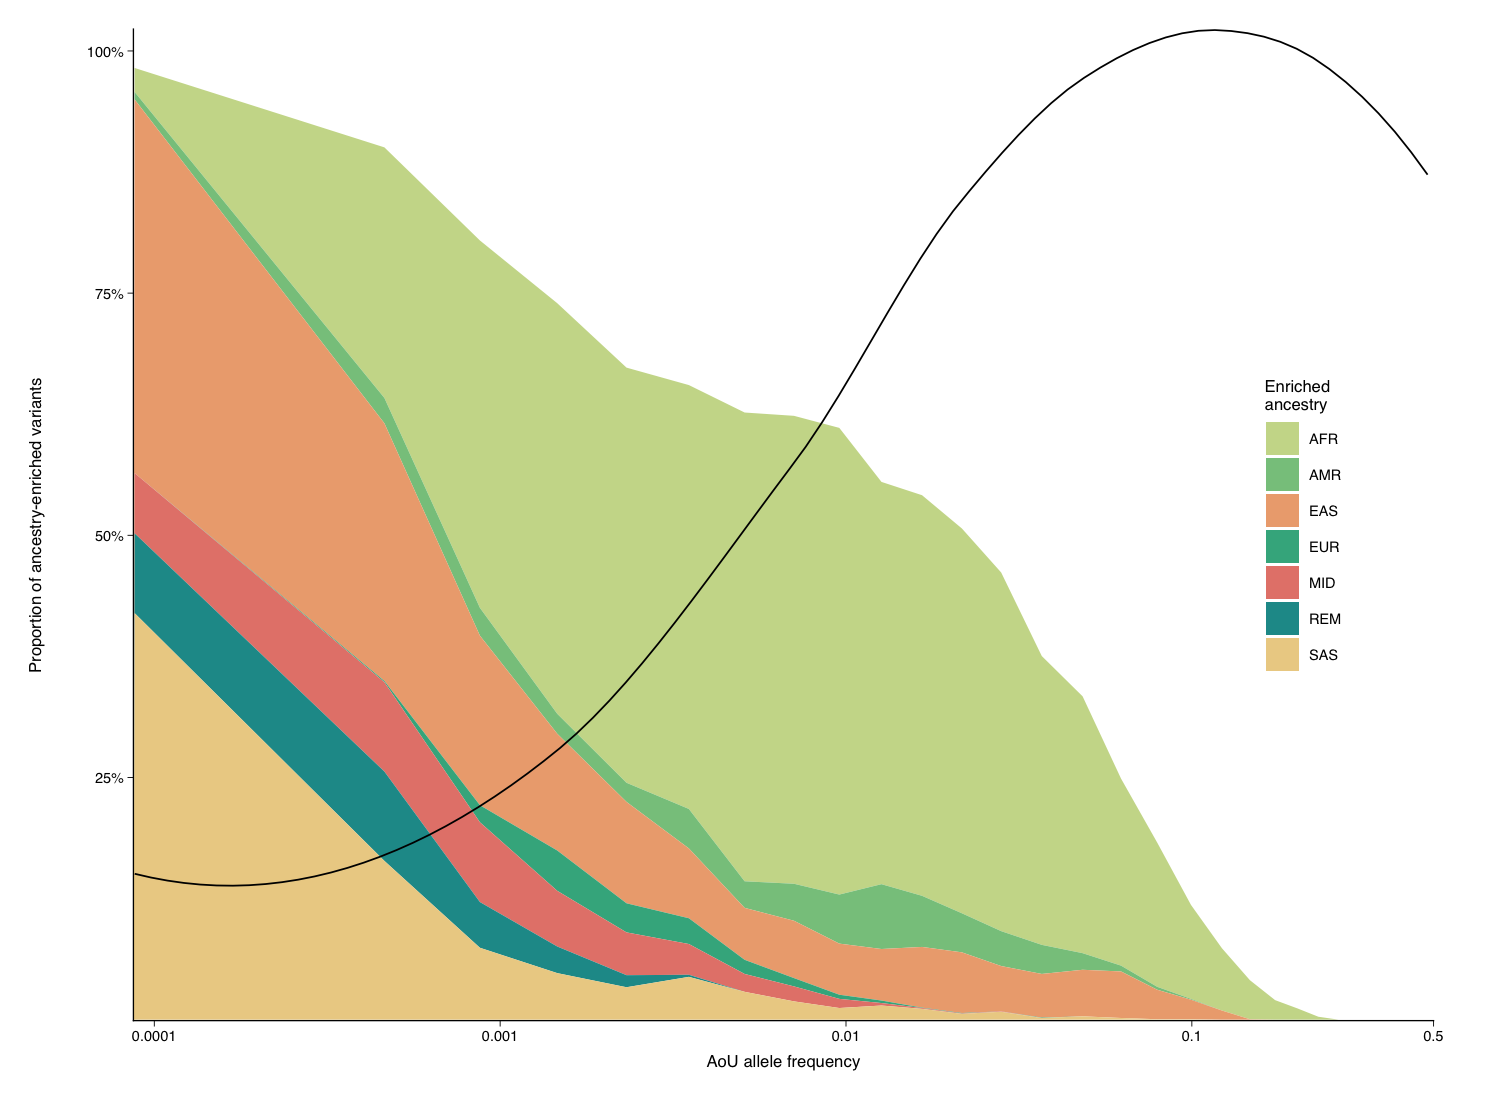

In [8]:
figure <- fig2_plot_s16(bins)
print(figure)


## Save aggregate outputs

Save the plot and aggregate variant counts. No participant records are used.


In [9]:
save_plot(figure, "supplements/S16", 184, 125)
readr::write_tsv(figure$data %>% select(af_bin, gvs_max_subpop, n_enriched, total_variants, prop, x) %>%
                   mutate(gvs_max_subpop = recode(as.character(gvs_max_subpop), OTH = "REM", oth = "REM")),
                 output_file("supplements/S16_frequency_bins.tsv"))


Export aggregate plot: supplements/S16


`geom_smooth()` using method = 'loess' and formula = 'y ~ x'

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'